In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

### WTIの時系列データを取得

In [3]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
response = request_api.update_commodity_timeseries_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [4]:
wti_df = request_api.get_commodity_time_series_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
wti_df.head()

取得件数: 6573


,id,commodity_id,commodity_code,commodity_market,date,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,6530,2,CL=F,None,2000-08-23,32.049999,32.799999,31.950001,31.950001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,6531,2,CL=F,None,2000-08-24,31.629999,32.240002,31.400000,31.900000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,6532,2,CL=F,None,2000-08-25,32.049999,32.099998,31.320000,31.700001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6533,2,CL=F,None,2000-08-28,32.869999,32.919998,31.860001,32.040001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,6534,2,CL=F,None,2000-08-29,32.720001,33.029999,32.560001,32.820000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [5]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [6]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 7027


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1064856,^GSPC,None,1998-11-17,1139.319946,1151.709961,1129.670044,1135.869995,705200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1064857,^GSPC,None,1998-11-18,1144.479980,1144.520020,1133.069946,1139.319946,652510000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1064858,^GSPC,None,1998-11-19,1152.609985,1155.099976,1144.420044,1144.479980,671000000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1064859,^GSPC,None,1998-11-20,1163.550049,1163.550049,1152.609985,1152.609985,721200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1064860,^GSPC,None,1998-11-23,1188.209961,1188.209961,1163.550049,1163.550049,774100000,1147.165991,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### SLBの時系列データを取得

In [7]:
slb = 'SLB'

response = request_api.update_stock_timeseries_data(
    code=slb,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [8]:
slb_timeseries_df = request_api.get_stock_time_series_data(
    code=slb,
    market=None,
    start=start,
    end=end
)
slb_timeseries_df

取得件数: 7027


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1081200,SLB,None,1998-11-17,13.159982,13.322050,13.095154,13.176189,3853800,NaN,...,NaN,NaN,False,63.0143,NaN,NaN,NaN,NaN,NaN,False
1,1081201,SLB,None,1998-11-18,12.884460,13.208598,12.641357,13.095150,7294600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1081202,SLB,None,1998-11-19,12.900660,13.030314,12.608936,12.965487,5852800,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1081203,SLB,None,1998-11-20,13.338252,13.516528,13.078942,13.143770,7822400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1081204,SLB,None,1998-11-23,12.933082,13.322046,12.852047,13.322046,7803200,13.140528,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7022,1322450,SLB,None,2026-10-20,49.980000,50.139999,49.070000,49.840000,11656600,49.100000,...,48.590699,-61.973875,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7023,1322451,SLB,None,2026-10-21,51.099998,51.240002,49.919998,49.980000,10843000,49.224000,...,48.631925,-66.336549,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7024,1332285,SLB,None,2026-10-22,49.549999,51.160000,48.700001,51.000000,14994000,49.770000,...,48.640900,-70.426022,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7025,1332286,SLB,None,2026-10-23,53.060001,53.450001,49.480000,49.959999,19057300,49.960000,...,48.613863,-71.945701,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### チャート

In [9]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
        #df_silver: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_wti is not None:
        df["MA50_WTI"] = df_wti_tmp["ma50"].reindex(df.index)
        df["MA200_WTI"] = df_wti_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_WTI"],
                name="WTI_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_WTI"],
                name="WTI_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [10]:
name = "Slb NV"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=slb,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 662


In [11]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{slb}_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/SLB_2025-01-01_2026-10-27.png


In [12]:
name = "Slb NV"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
#end = dt.datetime(2026, 4, 17).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=slb,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 662


#### 時系列データを保存

In [13]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{slb}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
slb_df = slb_timeseries_df.copy()
slb_df = slb_df.reset_index()
slb_df["date"] = pd.to_datetime(slb_df["date"])
slb_df = slb_df.set_index("date")
slb_df = slb_df.loc['2026-01-01':end]
slb_df.to_csv(output_path)
slb_df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6822,1088022,SLB,None,39.550674,39.786796,37.455078,37.789586,14637200,37.537720,...,36.131106,75.539998,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,6823,1088023,SLB,None,43.092522,44.430555,41.833198,42.305444,56362600,38.529438,...,36.178852,75.539998,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-06,6824,1088024,SLB,None,42.925270,43.850085,42.718659,43.564769,28955400,39.794666,...,36.221761,75.539998,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6825,1088025,SLB,None,41.685619,43.190909,41.518367,43.181068,17255900,40.953638,...,36.341070,75.531461,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6826,1088026,SLB,None,43.712345,43.850083,41.970935,42.167705,20138500,41.801714,...,36.558634,75.975412,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Fibonacci Extension

{'fib_levels_down': {'1.000': np.float64(44.35983164327922),
  '1.272': np.float64(40.06547418289304),
  '1.382': np.float64(38.32878550406039),
  '1.618': np.float64(34.602798884019435)},
 'fib_levels_up': {'1.272': np.float64(64.44226800214402),
  '1.382': np.float64(66.17895668097667),
  '1.618': np.float64(69.90494330101762),
  '2.000': np.float64(75.93598944023645)},
 'swing_high': np.float64(60.14791054175784),
 'swing_low': np.float64(44.35983164327922),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-02   6822  1088022        SLB         None  39.550674  39.786796   
 1   2026-01-05   6823  1088023        SLB         None  43.092522  44.430555   
 2   2026-01-06   6824  1088024        SLB         None  42.925270  43.850085   
 3   2026-01-07   6825  1088025        SLB         None  41.685619  43.190909   
 4   2026-01-08   6826  1088026        SLB         None  43.712345  43.850083   
 ..         ...    ...      ...  

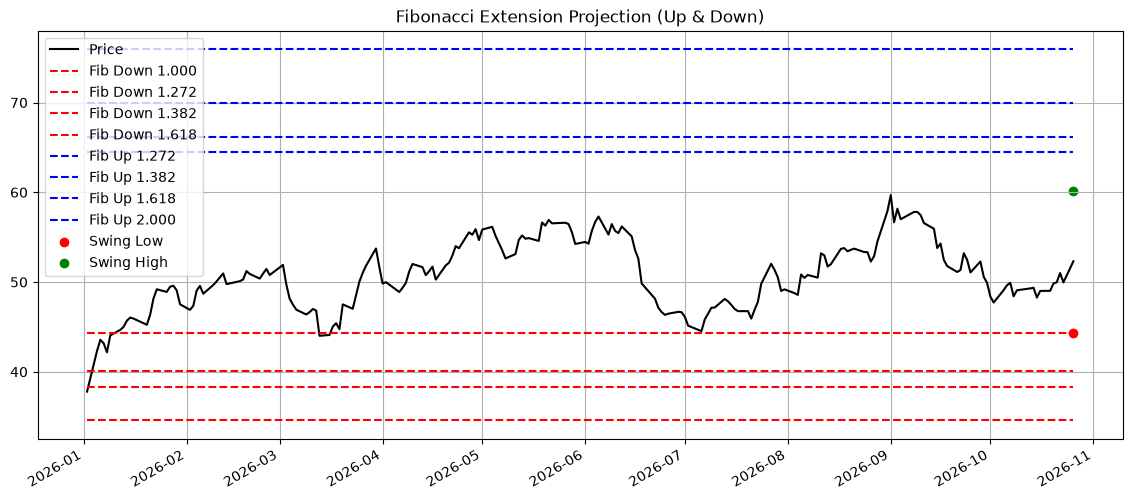

In [14]:
fib_result = fibonacci_extension.compute_fibonacci_extension(slb_df.copy().reset_index())
fib_result

In [15]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{slb}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()

# 保存
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")

#### 財務データ

In [16]:
response = request_api.update_corp_finance_data(
    code=slb,
    market=None
)
response

{'result': True}

In [17]:
slb_financials_data = request_api.get_corp_financials_data(code=slb, market=None)
slb_balance_sheet_data = request_api.get_corp_balance_sheet_data(code=slb, market=None)
slb_cash_flow_data = request_api.get_corp_cash_flow_data(code=slb, market=None)
slb_earnings_data = request_api.get_corp_earnings_data(code=slb, market=None)
slb_quarterly_earnings_data = request_api.get_corp_quarterly_earnings_data(code=slb, market=None)

In [18]:
# ４年分の財務データ
slb_financials_data_df = pd.DataFrame(slb_financials_data['results'])
# ４年分のバランスシート
slb_balance_sheet_data_df = pd.DataFrame(slb_balance_sheet_data['results'])
# ４年分のキャッシュフロー
slb_cash_flow_data_df = pd.DataFrame(slb_cash_flow_data['results'])
# ４年分の収益データ
slb_earnings_data_df = pd.DataFrame(slb_earnings_data['results'])
# ４年分の四半期収益データ
slb_quarterly_earnings_data_df = pd.DataFrame(slb_quarterly_earnings_data['results'])

In [19]:
"""
◆ 1. 株価・市場データ
• 現在株価（Price）
• 時価総額（Market Cap）
• 出来高（Volume）
• 52週高値・安値
• Beta（ボラティリティ指標）ß
"""
stock_prices_market_data.stock_prices_and_market_data(
    code=slb,
    market=None,
    bs_df=slb_balance_sheet_data_df
)

取得件数: 461
取得件数: 461
取得件数: 460
取得件数: 460
取得件数: 458
取得件数: 458
取得件数: 459
取得件数: 459
取得件数: 458
取得件数: 458


,close,market_cap,shares_outstanding,higher_rate_par_52_weeks,lower_rate_par_52_weeks,beta
0,21.565055,NaN,NaN,32.868667,10.288475,1.681011
1,26.451063,3.793581e+10,1.434188e+09,50.967829,21.771738,0.854274
2,39.138788,5.635203e+10,1.439800e+09,57.507731,27.747735,0.898032
3,47.468756,6.830044e+10,1.438850e+09,57.507731,34.827511,0.915129
4,48.497415,7.664199e+10,1.580331e+09,52.099165,29.874789,1.034849


In [20]:
"""
◆ 2. 財務データ（Financials）+ EPS（Earnings Per Share）+ PBR（Price-to-Book Ratio）
• 売上高（Revenue）
• 営業利益（Operating Income）
• 純利益（Net Income）
• EBITDA（企業による）
• 総資産（Total Assets）
• 総負債（Total Liabilities）
• 現金（Cash）
• 希釈EPS（Diluted EPS）
• 基本EPS（Basic EPS）
• 営業キャッシュフロー（Operating Cash Flow）
• フリーキャッシュフロー（Free Cash Flow）
"""
financial_df = financial.calc_financial(
    code = slb,
    market = None,
)
financial_df.to_markdown()

取得件数: 6953


'|    | date                |      revenue |    earnings |   total_assets |   total_debt |   cash_and_cash_equivalents |    EBITDA |   operating_income |   basic_eps |   diluted_eps |   operating_cash_flow |   free_cash_flow |\n|---:|:--------------------|-------------:|------------:|---------------:|-------------:|----------------------------:|----------:|-------------------:|------------:|--------------:|----------------------:|-----------------:|\n|  0 | 2021-12-31 00:00:00 | nan          | nan         |   nan          | nan          |                 nan         | 0         |        nan         |   nan       |        nan    |           nan         |      nan         |\n|  1 | 2022-12-31 00:00:00 |   2.8091e+10 |   3.441e+09 |     4.3135e+10 |   1.2226e+10 |                   1.655e+09 | 6.43e+09  |          4.151e+09 |     2.43009 |          2.39 |             3.72e+09  |        2.005e+09 |\n|  2 | 2023-12-31 00:00:00 |   3.3135e+10 |   4.203e+09 |     4.7957e+10 |   1.1965e+10 |  